# Adding Problem: Long-Term Dependency Learning Task

This notebook implements the adding problem, a benchmark task for evaluating the ability of RNNs to learn long-term dependencies. The task requires computing the sum of two specific numbers from a sequence of random numbers.

## Task Description

- Input: 2-dimensional vector at each time step
  - First dimension: Random number in [0, 1]
  - Second dimension: Boolean indicator (1 for numbers to add, 0 otherwise)
- Sequence length: 20 time steps
- Objective: Sum the two numbers where the boolean indicator is 1
- This tests the network's ability to remember and combine information from different time steps

We will compare the performance of two network architectures:

1. **Net**: RNN with excitatory/inhibitory separation
2. **SimpleNet**: Standard vanilla RNN


## 1. Setup and Imports


In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import warnings
warnings.filterwarnings('ignore')

# from pdm_model import Net, SimpleNet
from net.common import init_model

# Set device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

Using device: cuda


## 2. Adding Problem Dataset


In [2]:
class SortDataset(Dataset):
    def __init__(self, seq_len=64, num_samples=100000):
        self.seq_len = seq_len
        self.num_samples = num_samples
        number = torch.rand(num_samples, seq_len)
        argsort = torch.argsort(number, dim=1)
        # argsort_till_t = torch.zeros(num_samples, seq_len, seq_len)
        # for i in range(seq_len):
        #     argsort_till_t[:, i, :i+1] = torch.argsort(number[:, :i+1], dim=1, descending=False)
        #     argsort_till_t[:, i, i+1:] = -11  # padding with -1
        # self.argsort_till_t = argsort_till_t.to(torch.long)
        self.data = number.unsqueeze(-1)
        self.target = argsort
        self.input_size = 1
        self.output_size = seq_len**2

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        return self.data[idx], self.target[idx]

# Create datasets
train_dataset = SortDataset(seq_len=5, num_samples=50000)
test_dataset = SortDataset(seq_len=5, num_samples=1000)

print(f"Training dataset size: {len(train_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

# Show example
sample_input, sample_target = train_dataset[0]
print(f"\nExample input shape: {sample_input}")
print(f"Example target: {sample_target}")

Training dataset size: 50000
Test dataset size: 1000

Example input shape: tensor([[0.9708],
        [0.9122],
        [0.1740],
        [0.3038],
        [0.3827]])
Example target: tensor([2, 3, 4, 1, 0])


## 3. Visualize Sample Data


In [3]:
def visualize_adding_problem_sample(dataset, idx=0):
    """
    Visualize a sample from the adding problem dataset.
    """
    input_seq, target = dataset[idx]
    input_seq = input_seq[0]
    seq_len = input_seq.shape[0]

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

    # Plot the random numbers
    ax1.plot(range(seq_len), input_seq, 'b-', linewidth=2, label='Random numbers')
    # Highlight the numbers to be added
    marked_indices = np.where(input_seq == -1)[0]
    ax1.scatter(marked_indices, input_seq[marked_indices],
               color='red', s=100, zorder=5, label='Numbers to add')
    ax1.set_ylabel('Value')
    ax1.set_title(f'Adding Problem Sample (Target: {target})')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # Plot the indicators
    ax2.plot(range(seq_len), target, 'g-', linewidth=3, label='Target')
    ax2.set_xlabel('Time Step')
    ax2.set_ylabel('Target')
    ax2.set_ylim(-0.1, 1.1)
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


    print(f"Target: {target}")

# Visualize a few samples
# visualize_adding_problem_sample(train_dataset, 0)
# visualize_adding_problem_sample(train_dataset, 1)

In [4]:
def loss_fn(outputs, targets, criterion):
    """
    Compute cross-entropy loss between model outputs and targets.
    """
    T, B, D = outputs.shape
    predictions = outputs.reshape(T, B, T, T)
    assert targets.shape == (B, T, T)
    loss = 0
    acc = 0
    for t in range(T):
        prediction_t = predictions[t, :, :t+1].reshape(B*(t+1), T)
        target_t = targets[:, t, :t+1].reshape(B*(t+1))
        assert torch.all(target_t != -1)
        loss += criterion(prediction_t, target_t)
    loss /= T
    acc = predictions[-1].argmax(dim=-1).eq(targets[:,-1]).float().mean().item()
    return loss, acc

## 4. Training Functions


In [5]:
def train_model(model, train_dataset, test_dataset, epochs=100, lr=0.001, batch_size=64):
    """
    Train a model on the adding problem.
    """
    if isinstance(model, Net):
        special_params, other_params = [], []
        for name, p in model.named_parameters():
            if name == "lstm.eimask_logit":   # 或者用 name.endswith("eimask_logit")
                special_params.append(p)
                # assert p.requires_grad, "eimask_logit should be trainable"
            else:
                other_params.append(p)
        optimizer = torch.optim.Adam([{'params': special_params, 'lr': lr*100},
                                      {'params': other_params, 'lr': lr}])
    else:
        # For SimpleNet, use a single learning rate
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    # criterion = nn.L1Loss()

    train_losses = torch.zeros(epochs)
    test_every = 100
    test_losses = torch.zeros(epochs // test_every)
    test_accs = torch.zeros(epochs // test_every)

    model.train()
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    loader = iter(train_loader)
    for epoch in range(epochs):
        # print(epoch)
        # Training
        total_train_loss = 0
        num_batches = 0

        # for batch_inputs, batch_targets in train_loader:
        try:
            batch_inputs, batch_targets = next(loader)
        except StopIteration:
            train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
            loader = iter(train_loader)
            batch_inputs, batch_targets = next(loader)
        batch_inputs = batch_inputs.to(device).transpose(0, 1)  # (seq_len, batch_size, input_size)
        # print('batch_inputs:', batch_inputs.shape)
        batch_targets = batch_targets.to(device)  # (batch_size, seq_len)
        B, T = batch_targets.shape

        # print('batch_targets:', batch_targets.shape)

        optimizer.zero_grad()

        # Forward pass
        outputs, eimask_logit, hidden = model(batch_inputs)

        predictions = outputs[-1].reshape(B, T, T).flatten(0,1)
        target = batch_targets.flatten(0,1)
        decoding_loss = criterion(predictions, target)
        # decoding_loss, acc = loss_fn(outputs, batch_targets, criterion)

        if model.entropy_loss:
            # eimask_prob = F.softmax(eimask_logit, dim=-1)
            # eimask_entropy = -torch.sum(eimask_prob * torch.log(eimask_prob + 1e-10), dim=-1)
            # entropy_loss = torch.mean(eimask_entropy)  # Add entropy regularization
            entropy_loss = model.get_ei_entropy_loss()
        else:
            entropy_loss = 0.0

        if isinstance(model, SimpleNet):
            l1_loss = model.lstm.Wrec_free.abs().mean()
        else:
            l1_loss = 0

        loss = 1 * entropy_loss + decoding_loss + l1_loss * 0
        # Backward pass
        loss.backward()
        # Gradient clipping for stability
        # torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()

        total_train_loss += loss.item()
        num_batches += 1

        avg_train_loss = total_train_loss / num_batches
        train_losses[epoch] = avg_train_loss

        # Testing
        if epoch % test_every == 0:
            model.eval()
            total_test_loss = 0
            total_test_accuracy = 0
            num_test_batches = 0

            with torch.no_grad():
                for batch_inputs, batch_targets in test_loader:
                    batch_inputs = batch_inputs.to(device).transpose(0, 1)
                    batch_targets = batch_targets.to(device)  # (batch_size, seq_len)
                    B, T = batch_targets.shape

                    outputs, _, hidden = model(batch_inputs)
                    # print('outputs:', outputs.shape)
                    predictions = outputs[-1].reshape(B, T, T).flatten(0,1)
                    target = batch_targets.flatten(0,1)

                    loss = criterion(predictions, target)
                    # loss, accuracy = loss_fn(outputs, batch_targets, criterion)
                    predict_label = torch.argmax(predictions, dim=-1)
                    accuracy = (predict_label == target).float().mean().item()
                    total_test_loss += loss.item()
                    total_test_accuracy += accuracy
                    num_test_batches += 1

            avg_test_loss = total_test_loss / num_test_batches
            avg_test_accuracy = total_test_accuracy / num_test_batches
            test_losses[epoch // test_every] = avg_test_loss
            test_accs[epoch // test_every] = avg_test_accuracy

            print(f'Epoch [{epoch:4d}/{epochs}], Train Loss: {avg_train_loss:.6f}, Test Loss: {avg_test_loss:.6f}, Test Acc: {avg_test_accuracy:.4f}')

            model.train()

    return train_losses, test_losses

def evaluate_model(model, test_loader):
    """
    Evaluate model performance on test set.
    """
    model.eval()
    total_loss = 0
    total_accuracy = 0
    predictions = []
    targets = []

    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for batch_inputs, batch_targets in test_loader:
            batch_inputs = batch_inputs.to(device).transpose(0, 1)
            batch_targets = batch_targets.to(device)
            B, T = batch_targets.shape

            outputs, _, hidden = model(batch_inputs)
            preds = outputs[-1].reshape(B, T, T).flatten(0,1)
            target = batch_targets.flatten(0,1)

            loss = criterion(preds, target)
            # loss, acc = loss_fn(outputs, batch_targets, criterion)
            total_loss += loss.item()
            # total_accuracy += acc

            predictions.extend(preds.cpu().numpy())
            targets.extend(batch_targets.cpu().numpy())

    avg_loss = total_loss / len(test_loader)
    accuracy = total_accuracy / len(test_loader)
    # print('type:', type(predictions), type(targets))
    # print(predictions, np.stack(predictions).shape)
    # print(targets, np.concatenate(targets).shape)
    # print('predictions shape:', np.stack(predictions).shape, 'targets shape:', np.concatenate(targets).shape)
    accuracy = np.mean((np.argmax(np.stack(predictions), axis=-1) == np.concatenate(targets)).astype(np.float32))

    return avg_loss, accuracy, predictions, targets

## 5. Experiment: Compare Net vs SimpleNet


In [6]:
# Experiment parameters
n_seeds = 5
epochs = 3000
batch_size = 64
hidden_size = 64
input_size = 1  # [number, indicator]
output_size = 25  # regression output

def multiple_train(lr_ei, lr_simple, n_seeds):
    # Create data loaders
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    # Storage for results
    results = {
        'net': {'train_losses': [], 'test_losses': [], 'final_acc': []},
        'simple': {'train_losses': [], 'test_losses': [], 'final_acc': []}
    }

    print(f"Running experiment with {n_seeds} seeds...\n")

    for seed in range(n_seeds):
        print(f"=== Seed {seed + 1}/{n_seeds} ===")

        # Set random seeds for reproducibility
        torch.manual_seed(seed)
        np.random.seed(seed)

        # Train Net (EI-separated RNN)
        print("Training Net (EI-separated RNN)...")
        net = Net(ob_size=input_size, num_h=hidden_size, act_size=output_size, entropy_loss=True).to(device)
        train_losses_net, test_losses_net = train_model(net, train_dataset, test_dataset,
                                                    epochs=epochs, lr=lr_ei, batch_size=batch_size,)

        # Evaluate Net
        _, acc_net, net_predictions, net_targets = evaluate_model(net, test_loader)

        results['net']['train_losses'].append(train_losses_net)
        results['net']['test_losses'].append(test_losses_net)
        results['net']['final_acc'].append(acc_net)
        print(f"Net - Final Acc: {acc_net:.6f}")


        # Train SimpleNet (vanilla RNN)
        print("Training SimpleNet (vanilla RNN)...")
        simple_net = SimpleNet(ob_size=input_size, num_h=hidden_size, act_size=output_size).to(device)
        train_losses_simple, test_losses_simple = train_model(simple_net, train_dataset, test_dataset,
                                                            epochs=epochs,lr=lr_simple,batch_size=batch_size,)

        # Evaluate SimpleNet
        _, acc_simple, simple_predictions, simple_targets = evaluate_model(simple_net, test_loader)

        results['simple']['train_losses'].append(train_losses_simple.detach().cpu().numpy())
        results['simple']['test_losses'].append(test_losses_simple.detach().cpu().numpy())
        results['simple']['final_acc'].append(acc_simple)
        print(f"SimpleNet - Final Acc: {acc_simple:.6f}")




        print()

    print("Experiment completed!")
    return results

In [8]:
test_dict = []
lr_all = [1e-4, 1e-3, 1e-2, 1e-1]
n_seed = 5
for lr in lr_all:
    print(f"Learning Rate: {lr}")
    result = multiple_train(lr_ei=lr, lr_simple=lr, n_seeds=n_seed)
    test_dict.append({'lr': lr, 'result': result})

Learning Rate: 0.0001
Running experiment with 5 seeds...

=== Seed 1/5 ===
Training Net (EI-separated RNN)...
Epoch [   0/3000], Train Loss: 2.491543, Test Loss: 1.737588, Test Acc: 0.1925
Epoch [ 100/3000], Train Loss: 2.276487, Test Loss: 1.648250, Test Acc: 0.1925
Epoch [ 200/3000], Train Loss: 2.077241, Test Loss: 1.629538, Test Acc: 0.1925
Epoch [ 300/3000], Train Loss: 1.884252, Test Loss: 1.618744, Test Acc: 0.1990
Epoch [ 400/3000], Train Loss: 1.770747, Test Loss: 1.612527, Test Acc: 0.1938
Epoch [ 500/3000], Train Loss: 1.706129, Test Loss: 1.609308, Test Acc: 0.1939
Epoch [ 600/3000], Train Loss: 1.676211, Test Loss: 1.607797, Test Acc: 0.2208
Epoch [ 700/3000], Train Loss: 1.654698, Test Loss: 1.606992, Test Acc: 0.2277
Epoch [ 800/3000], Train Loss: 1.645792, Test Loss: 1.606821, Test Acc: 0.2457
Epoch [ 900/3000], Train Loss: 1.635738, Test Loss: 1.606307, Test Acc: 0.2342
Epoch [1000/3000], Train Loss: 1.629501, Test Loss: 1.605269, Test Acc: 0.2485
Epoch [1100/3000], Tr

## 6. Results Analysis


ei_acc: [[0.27772    0.0068511 ]
 [0.69635999 0.01059464]
 [0.87804002 0.0044657 ]
 [0.81076002 0.01518126]]


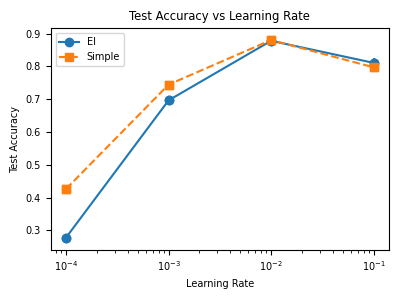

In [12]:
ei_acc = np.zeros((len(lr_all), 2))
simple_acc = np.zeros((len(lr_all), 2))
for i, dic in enumerate(test_dict):
    ei_acc_all = np.array(dic['result']['net']['final_acc'])
    simple_acc_all = np.array(dic['result']['simple']['final_acc'])
    ei_acc[i, 0] = np.mean(ei_acc_all)
    ei_acc[i, 1] = np.std(ei_acc_all)
    simple_acc[i, 0] = np.mean(simple_acc_all)
    simple_acc[i, 1] = np.std(simple_acc_all)
fig, ax = plt.subplots(figsize=(4,3))
print('ei_acc:', ei_acc)
ax.plot(lr_all, ei_acc[:,0], 'o-', label='EI', color='C0')
ax.errorbar(lr_all, ei_acc[:,0], yerr=ei_acc[:,1], fmt='o', color='C0')
ax.plot(lr_all, simple_acc[:,0], 's--', label='Simple', color='C1')
ax.errorbar(lr_all, simple_acc[:,0], yerr=simple_acc[:,1], fmt='s', color='C1')
ax.set_xscale('log')
ax.set_xlabel('Learning Rate')
ax.set_ylabel('Test Accuracy')
ax.set_title('Test Accuracy vs Learning Rate')
ax.legend()
plt.tight_layout()
plt.show()
plt.close()

In [23]:
# Print summary statistics
print("=== Final Results Summary ===")
print(f"Number of seeds: {n_seeds}")
print(f"Training epochs: {epochs}")
print(f"Hidden size: {hidden_size}")
print(f"Sequence length: 20")
print()

# Net results
net_acc_mean = np.mean(results['net']['final_acc'])
net_acc_std = np.std(results['net']['final_acc'])

print(f"Net (EI-separated RNN):")
print(f"  Acc: {net_acc_mean:.6f} ± {net_acc_std:.6f}")

# SimpleNet results
simple_acc_mean = np.mean(results['simple']['final_acc'])
simple_acc_std = np.std(results['simple']['final_acc'])

print(f"\nSimpleNet (vanilla RNN):")
print(f"  MSE: {simple_acc_mean:.6f} ± {simple_acc_std:.6f}")

# Improvement calculation
acc_improvement = (net_acc_mean - simple_acc_mean) / simple_acc_mean * 100

print(f"\n=== Performance Comparison ===")
print(f"Acc improvement (Net vs SimpleNet): {acc_improvement:.2f}%")

if acc_improvement > 0:
    print("Net (EI-separated) performs better than SimpleNet (vanilla RNN)")
else:
    print("SimpleNet (vanilla RNN) performs better than Net (EI-separated)")

=== Final Results Summary ===
Number of seeds: 5
Training epochs: 3000
Hidden size: 64
Sequence length: 20

Net (EI-separated RNN):
  Acc: 0.875600 ± 0.004630

SimpleNet (vanilla RNN):
  MSE: 0.867720 ± 0.014025

=== Performance Comparison ===
Acc improvement (Net vs SimpleNet): 0.91%
Net (EI-separated) performs better than SimpleNet (vanilla RNN)


## 7. Visualization


net train mean: [2.5107236  2.013249   1.7694988  ... 0.29913473 0.25840482 0.28710446]
(array([], dtype=int64), array([], dtype=int64))


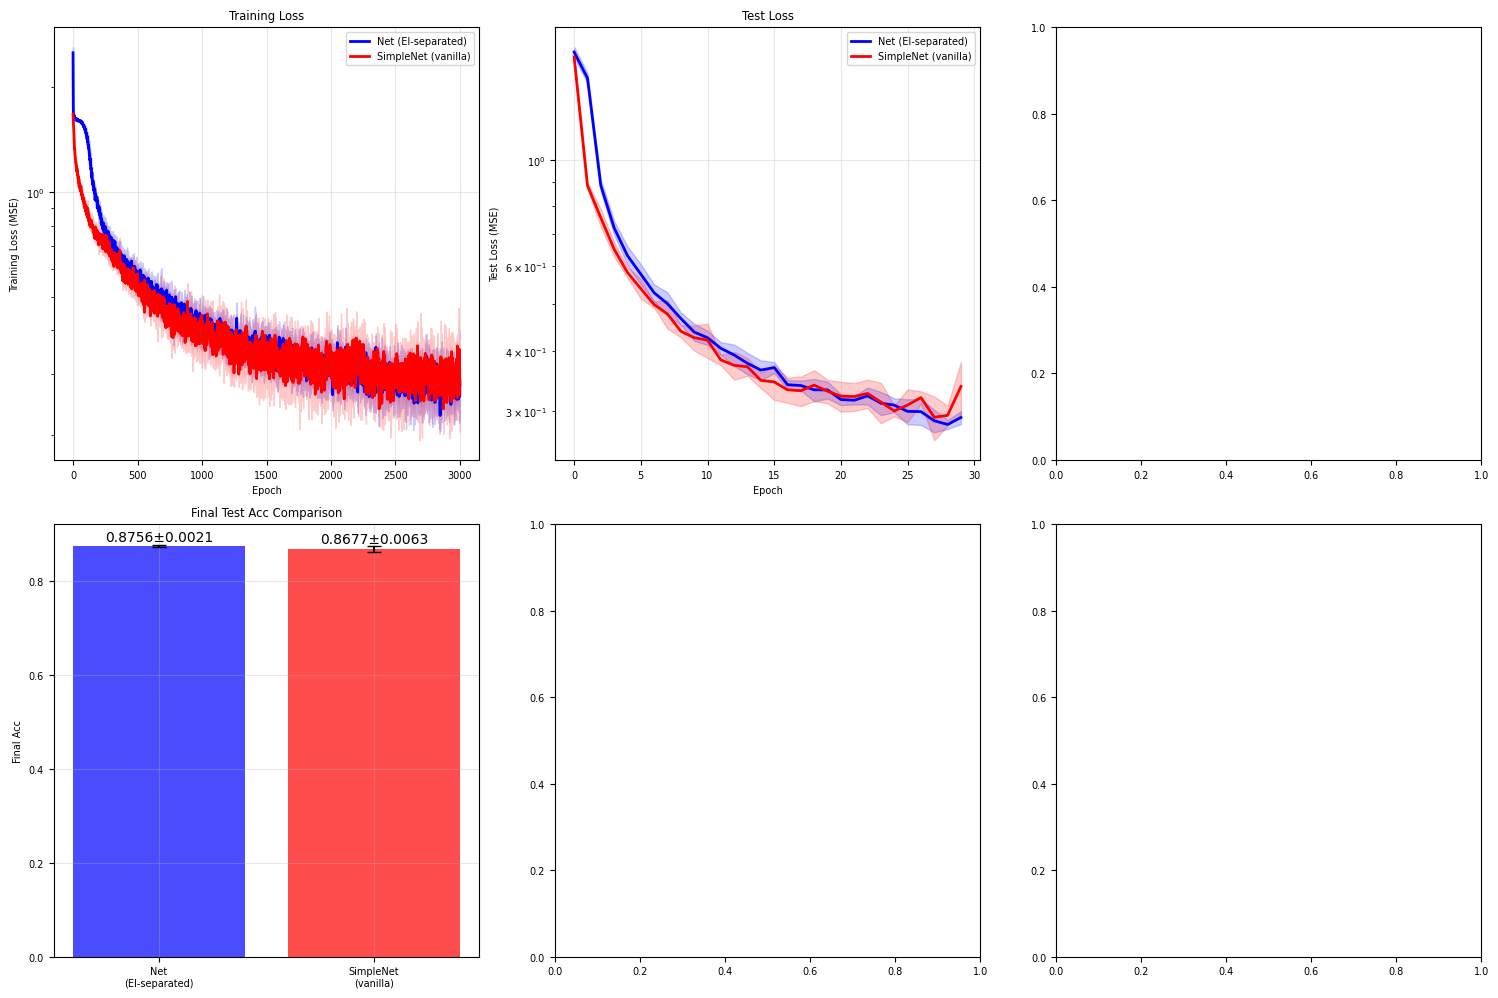

In [18]:
def plot_learning_curves(results, n_seeds):
    """
    Plot learning curves for both models.
    """
    fig, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(2, 3, figsize=(15, 10))

    # Training loss curves
    net_train_losses = np.array(results['net']['train_losses'])
    simple_train_losses = np.array(results['simple']['train_losses'])

    net_train_mean = np.mean(net_train_losses, axis=0)
    net_train_std = np.std(net_train_losses, axis=0)
    simple_train_mean = np.mean(simple_train_losses, axis=0)
    simple_train_std = np.std(simple_train_losses, axis=0)
    print('net train mean:', net_train_mean)
    print(np.where(net_train_losses>100))

    epochs_range = range(len(net_train_mean))

    ax1.plot(epochs_range, net_train_mean, 'b-', label='Net (EI-separated)', linewidth=2)
    ax1.fill_between(epochs_range, net_train_mean - net_train_std, net_train_mean + net_train_std, alpha=0.2, color='blue')
    ax1.plot(epochs_range, simple_train_mean, 'r-', label='SimpleNet (vanilla)', linewidth=2)
    ax1.fill_between(epochs_range, simple_train_mean - simple_train_std, simple_train_mean + simple_train_std, alpha=0.2, color='red')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Training Loss (MSE)')
    ax1.set_title('Training Loss')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.set_yscale('log')

    # Test loss curves (subset of epochs)
    if results['net']['test_losses'][0] is not None:  # Check if test losses exist
        net_test_losses = np.array(results['net']['test_losses'])
        simple_test_losses = np.array(results['simple']['test_losses'])

        net_test_mean = np.mean(net_test_losses, axis=0)
        net_test_std = np.std(net_test_losses, axis=0)
        simple_test_mean = np.mean(simple_test_losses, axis=0)
        simple_test_std = np.std(simple_test_losses, axis=0)

        test_epochs = range(0, len(net_train_mean))[:len(net_test_mean)]

        ax2.plot(test_epochs, net_test_mean, 'b-', label='Net (EI-separated)', linewidth=2)
        ax2.fill_between(test_epochs, net_test_mean - net_test_std, net_test_mean + net_test_std, alpha=0.2, color='blue')
        ax2.plot(test_epochs, simple_test_mean, 'r-', label='SimpleNet (vanilla)', linewidth=2)
        ax2.fill_between(test_epochs, simple_test_mean - simple_test_std, simple_test_mean + simple_test_std, alpha=0.2, color='red')
        ax2.set_xlabel('Epoch')
        ax2.set_ylabel('Test Loss (MSE)')
        ax2.set_title('Test Loss')
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        ax2.set_yscale('log')

    # Final MSE comparison
    net_acc = results['net']['final_acc']
    simple_acc = results['simple']['final_acc']

    x_pos = [0, 1]
    acc_means = [np.mean(net_acc), np.mean(simple_acc)]
    acc_stds = [np.std(net_acc)/np.sqrt(len(net_acc)), np.std(simple_acc)/np.sqrt(len(simple_acc))]

    bars = ax4.bar(x_pos, acc_means, yerr=acc_stds, capsize=5,
                   color=['blue', 'red'], alpha=0.7,
                   label=['Net (EI-separated)', 'SimpleNet (vanilla)'])
    ax4.set_ylabel('Final Acc')
    ax4.set_title('Final Test Acc Comparison')
    ax4.set_xticks(x_pos)
    ax4.set_xticklabels(['Net\n(EI-separated)', 'SimpleNet\n(vanilla)'])
    ax4.grid(True, alpha=0.3)

    # Add value labels on bars
    for i, (bar, mean, std) in enumerate(zip(bars, acc_means, acc_stds)):
        ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + std + 0.001,
                f'{mean:.4f}±{std:.4f}', ha='center', va='bottom', fontsize=10)


    plt.tight_layout()
    plt.show()

# Plot the results
plot_learning_curves(results, n_seeds)

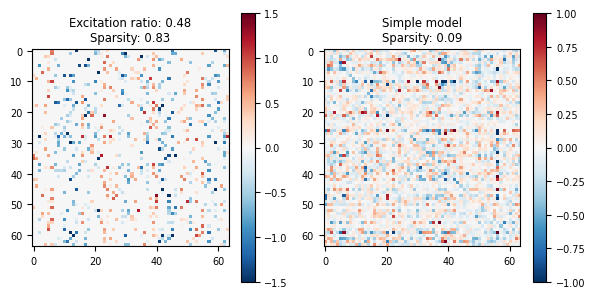

In [19]:
weight = net.get_actual_weight().detach().cpu().numpy()
fig, ax = plt.subplots(1,2,figsize=(6,3))
limit = 1.5
im = ax[0].imshow(weight, cmap='RdBu_r', vmin=-limit, vmax=limit)
sparsity = 1 - np.mean(np.abs(weight)>0.1*np.std(np.abs(weight)))
eimask = net.lstm.eimask_logit.detach().cpu().numpy()
# mask = F.gumbel_softmax(net.lstm.eimask_logit, tau=0.1, hard=False, dim=-1).detach().cpu().numpy()
exc_ratio = np.mean(eimask[:, 0] > eimask[:, 1])
ax[0].set_title(f'Excitation ratio: {exc_ratio:.2f}\nSparsity: {sparsity:.2f}')
plt.colorbar(im, ax=ax[0])

weight_simple = simple_net.get_actual_weight().detach().cpu().numpy()
im = ax[1].imshow(weight_simple, cmap='RdBu_r', vmin=-1, vmax=1)
sparsity_simple = 1 - np.mean(np.abs(weight_simple)>0.1*np.std(np.abs(weight_simple)))
ax[1].set_title(f'Simple model\nSparsity: {sparsity_simple:.2f}')
plt.colorbar(im, ax=ax[1])
plt.tight_layout()


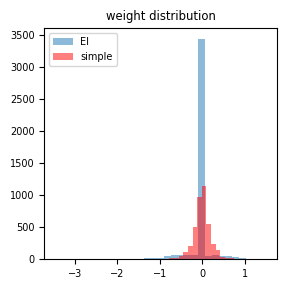

In [20]:
fig, ax = plt.subplots(1,1, figsize=(3,3))
ax.hist(weight.flatten(),bins=30, color='C0', label='EI', alpha=0.5)
ax.hist(weight_simple.flatten(),bins=30, color='red', label='simple', alpha=0.5)
ax.legend()
plt.title('weight distribution')
plt.show()

In [21]:
# torch.save(net.state_dict(), './model/sort/ei_net.pth')
# torch.save(simple_net.state_dict(), './model/sort/simple_net.pth')
# config = {'input_size': input_size, 'output_size':output_size,
#           'hidden_size': hidden_size, 'epochs': epochs,
#           'seq_len':5}
# with open('./model/sort/model_config.json','w',encoding='utf-8') as f:
#     import json
#     json.dump(config, f, ensure_ascii=False)

In [22]:
print(config)

NameError: name 'config' is not defined

## 8. Test Predictions Visualization


In [ ]:
from pdm_model import Net, SimpleNet
device='cuda:0'
batch_size = 64
hidden_size = 64
input_size = train_dataset.input_size  # [number, indicator]
output_size = train_dataset.output_size  # regression output
simple_net = SimpleNet(ob_size=input_size, num_h=hidden_size, act_size=output_size).to(device)
net = Net(ob_size=input_size, num_h=hidden_size, act_size=output_size, entropy_loss=True).to(device)
net_path = './model/sort/ei_net.pth'
simple_net_path = './model/sort/simple_net.pth'
net.load_state_dict(torch.load(net_path))
simple_net.load_state_dict(torch.load(simple_net_path))

<All keys matched successfully>

In [ ]:
n_test = 10
def plot_activity(hidden_size, net, idxs, color):
    fig, ax = plt.subplots((hidden_size-1)//8+1, 8, figsize=(32, (hidden_size//8+1)*3))
    ax = ax.flatten()
    input_seq, target = test_dataset[idxs]
    seq_len = input_seq.shape[1]


    batch_inputs = input_seq.transpose(0,1).to(device)
    outputs, eimask_logit, hidden = net(batch_inputs)
    h_all = hidden[0].detach().cpu().numpy()
    h_all_mean = h_all.mean(1)
    h_all_std = h_all.std(1)
    print('h_all_std:', h_all_std)
    for j in range(hidden_size):
        ax[j].plot(h_all_mean[:,j], color=color)
        ax[j].fill_between(np.arange(seq_len), h_all_mean[:,j]-h_all_std[:,j], h_all_mean[:,j]+h_all_std[:,j],
                           alpha=0.2, color=color)
    normalized_variance = (h_all_std/(h_all.max((0,1))-h_all.min((0,1)))).mean()

    plt.suptitle(f'Normalized variance: {normalized_variance:.4f}', fontsize=30)
    plt.tight_layout()
    plt.show()
    plt.close()

idxs = np.random.randint(0, len(test_dataset), n_test)

h_all_std: [[9.91956294e-02 8.84615537e-03 1.32133275e-01 1.26625702e-01
  1.10184036e-01 1.30676270e-01 9.52016115e-02 1.72861591e-01
  8.74038711e-02 1.94896519e-01 5.87107353e-02 1.95426583e-01
  2.80094564e-01 2.04111770e-01 8.67312402e-03 1.41722441e-01
  1.29433364e-01 2.20149115e-01 2.24364325e-01 1.34322524e+00
  2.88432002e-01 3.85942668e-01 1.22996666e-01 3.02443951e-01
  2.68819511e-01 4.91677672e-01 8.55095744e-01 6.07163869e-02
  4.26177353e-01 9.90496099e-01 4.38869715e-01 1.81905672e-01
  4.33370620e-02 4.22590487e-02 1.01534292e-01 1.12269178e-01
  8.83324325e-01 1.79774567e-01 2.08220735e-01 6.37970790e-02
  1.98102742e-01 2.04394221e-01 1.59469172e-01 2.76852757e-01
  5.23350835e-01 1.42557666e-01 1.84482300e+00 3.48889947e-01
  1.59671739e-01 2.86431432e-01 2.46029601e-01 8.12421918e-01
  1.74795941e-01 1.32835403e-01 1.86641201e-01 5.58971226e-01
  4.62919801e-01 1.37328655e-01 7.11787224e-01 1.21732779e-01
  7.31568132e-03 2.53362775e-01 3.04714084e-01 3.69679451e-

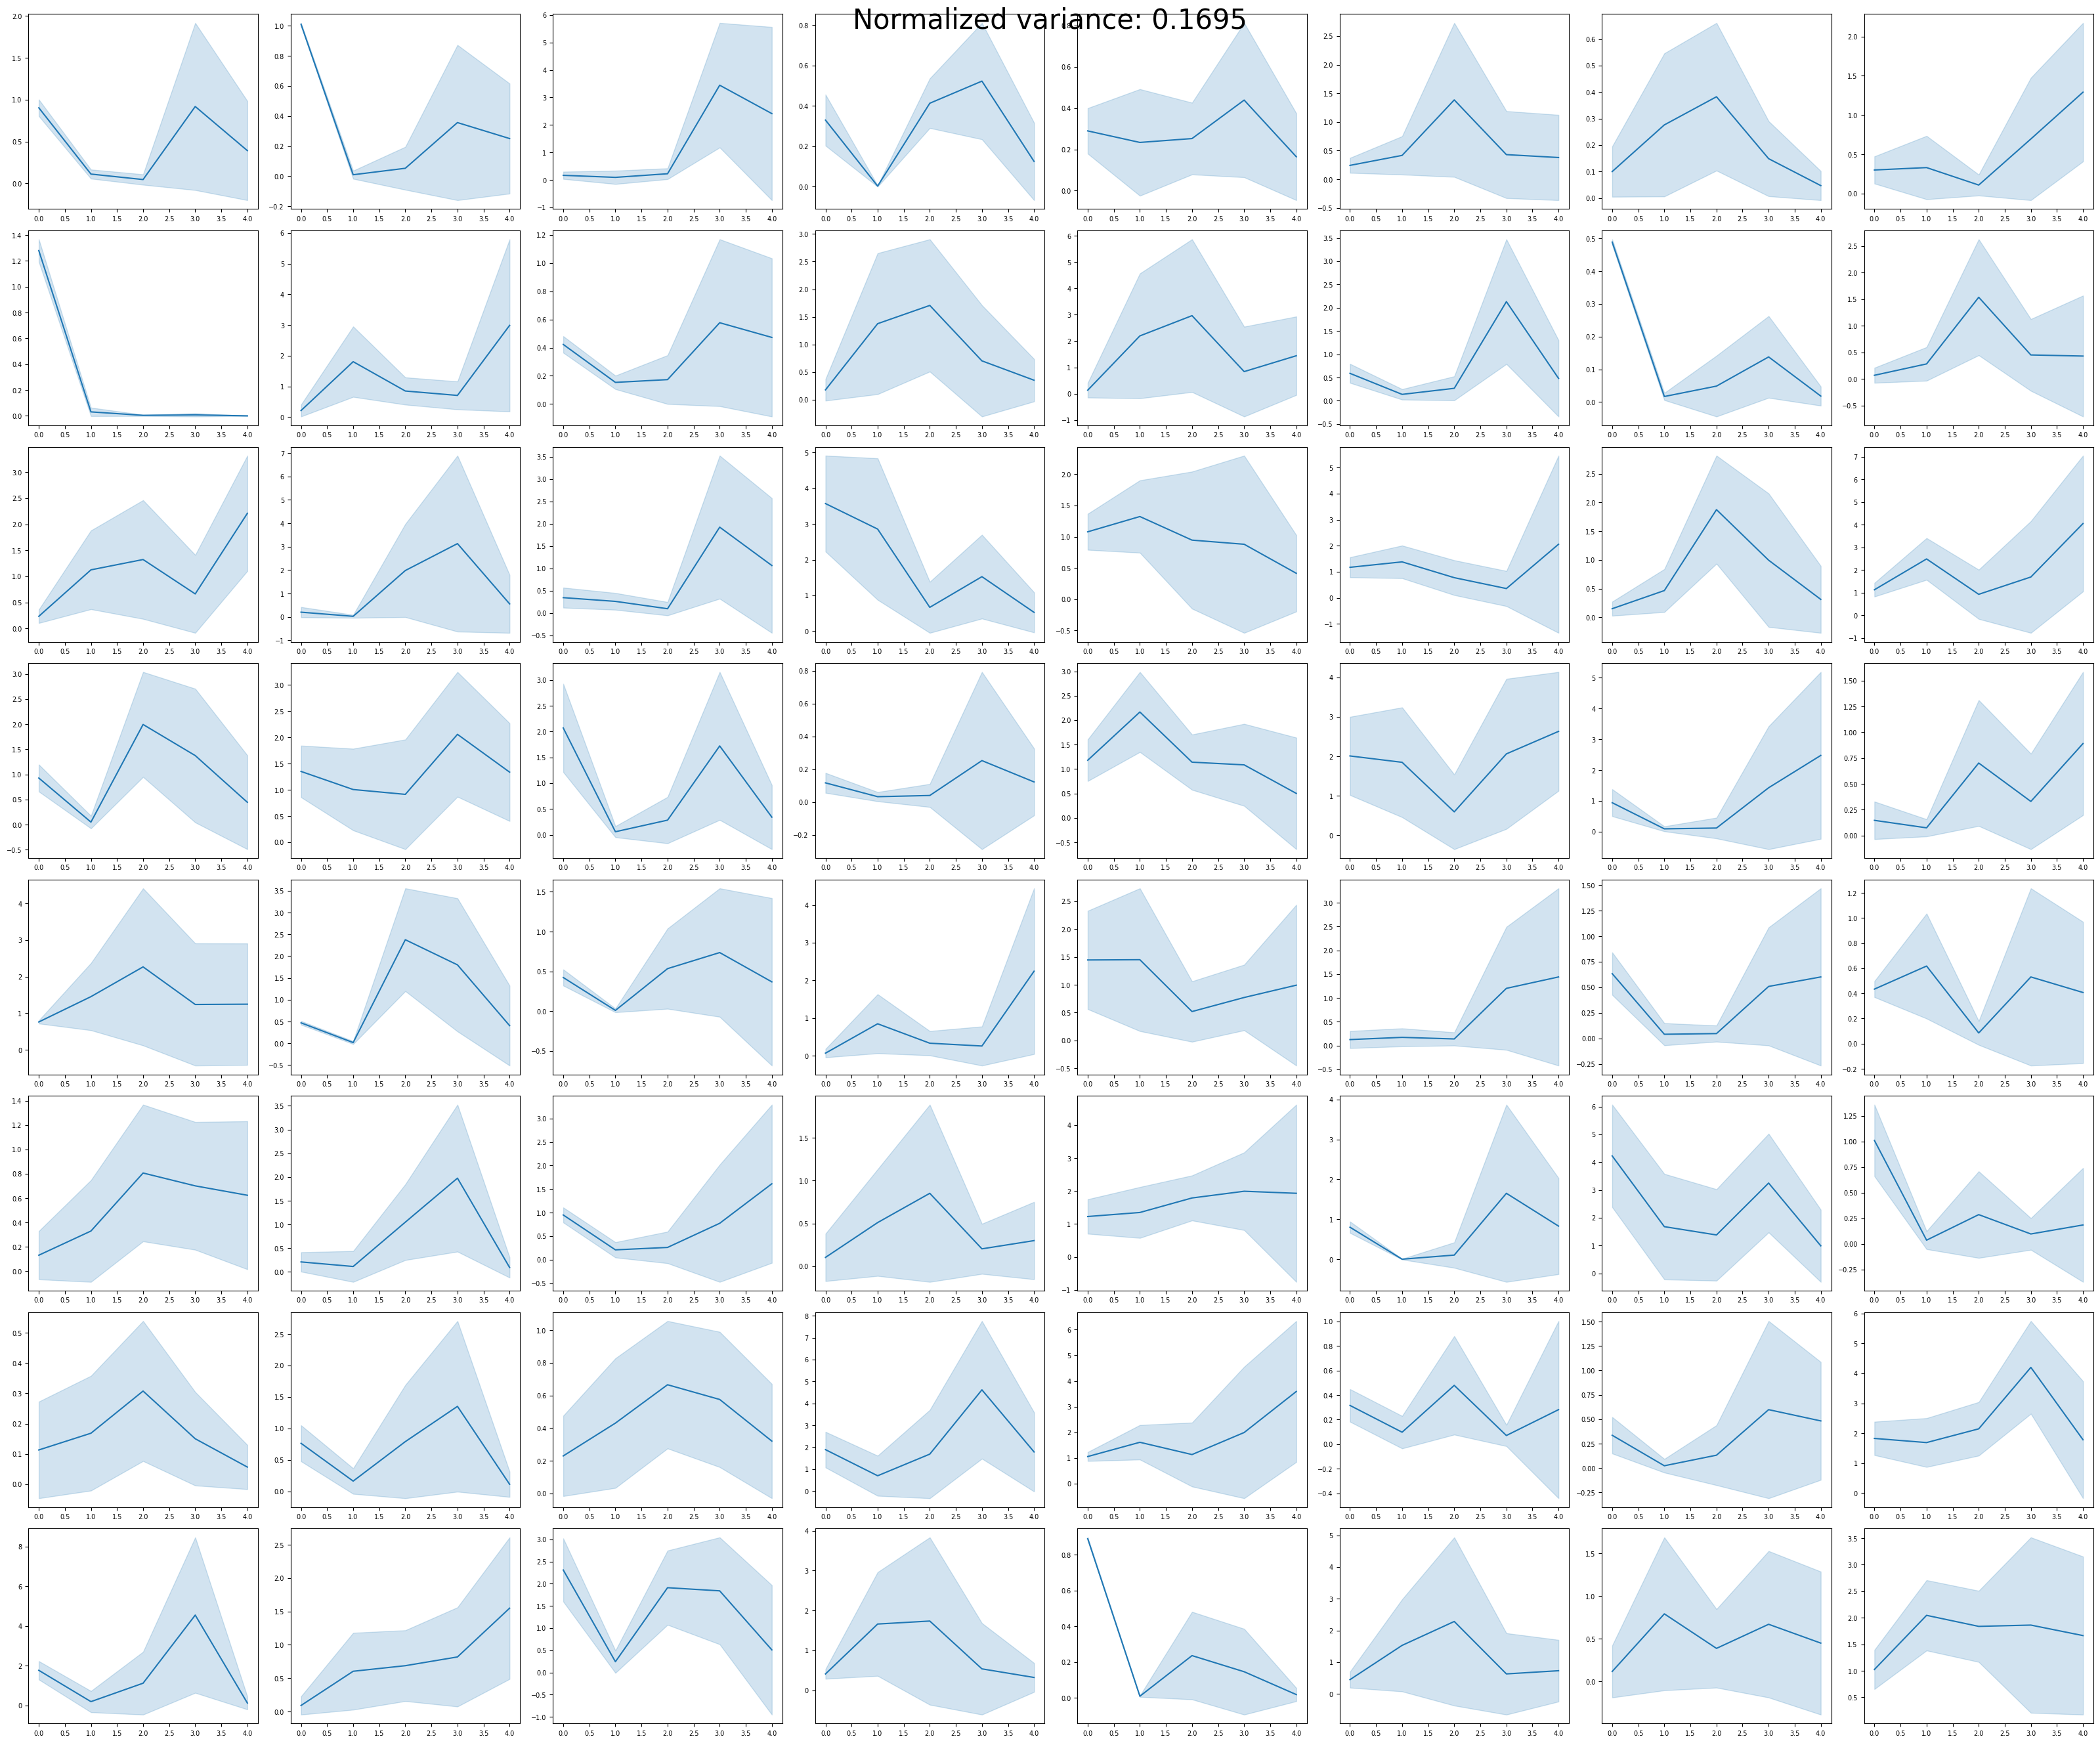

In [ ]:
plot_activity(hidden_size, net, idxs, 'C0')

h_all_std: [[2.32882872e-01 1.42309263e-01 1.84164494e-01 4.20816205e-02
  8.03576186e-02 1.51154995e-02 8.01347643e-02 3.95282567e-01
  2.17756361e-01 1.26124918e-01 2.22802043e-01 3.98579426e-02
  2.38282472e-01 1.46870404e-01 9.53826681e-02 1.17870241e-01
  1.72087044e-01 9.71857905e-02 9.80575010e-02 1.38792247e-01
  2.29633048e-01 2.86679000e-01 8.26091096e-02 1.14492103e-01
  1.63832769e-01 1.25911668e-01 3.04980367e-01 2.43001789e-01
  2.78197169e-01 1.04379907e-01 2.36493811e-01 1.49212584e-01
  1.65169418e-01 6.46447390e-02 3.68481666e-01 1.50490969e-01
  3.07170898e-01 1.72527328e-01 5.18926457e-02 1.15075849e-01
  2.98807889e-01 1.74411967e-01 1.54835522e-01 3.95684034e-01
  1.62514284e-01 1.07429579e-01 8.56412575e-02 2.85124063e-01
  1.51076287e-01 1.47128731e-01 1.13828309e-01 1.84457645e-01
  2.62584776e-01 1.22281961e-01 1.45026490e-01 2.93579608e-01
  1.51998490e-01 2.76242882e-01 7.04369321e-02 3.03244919e-01
  2.35547736e-01 2.52194583e-01 1.92027479e-01 1.39328375e-

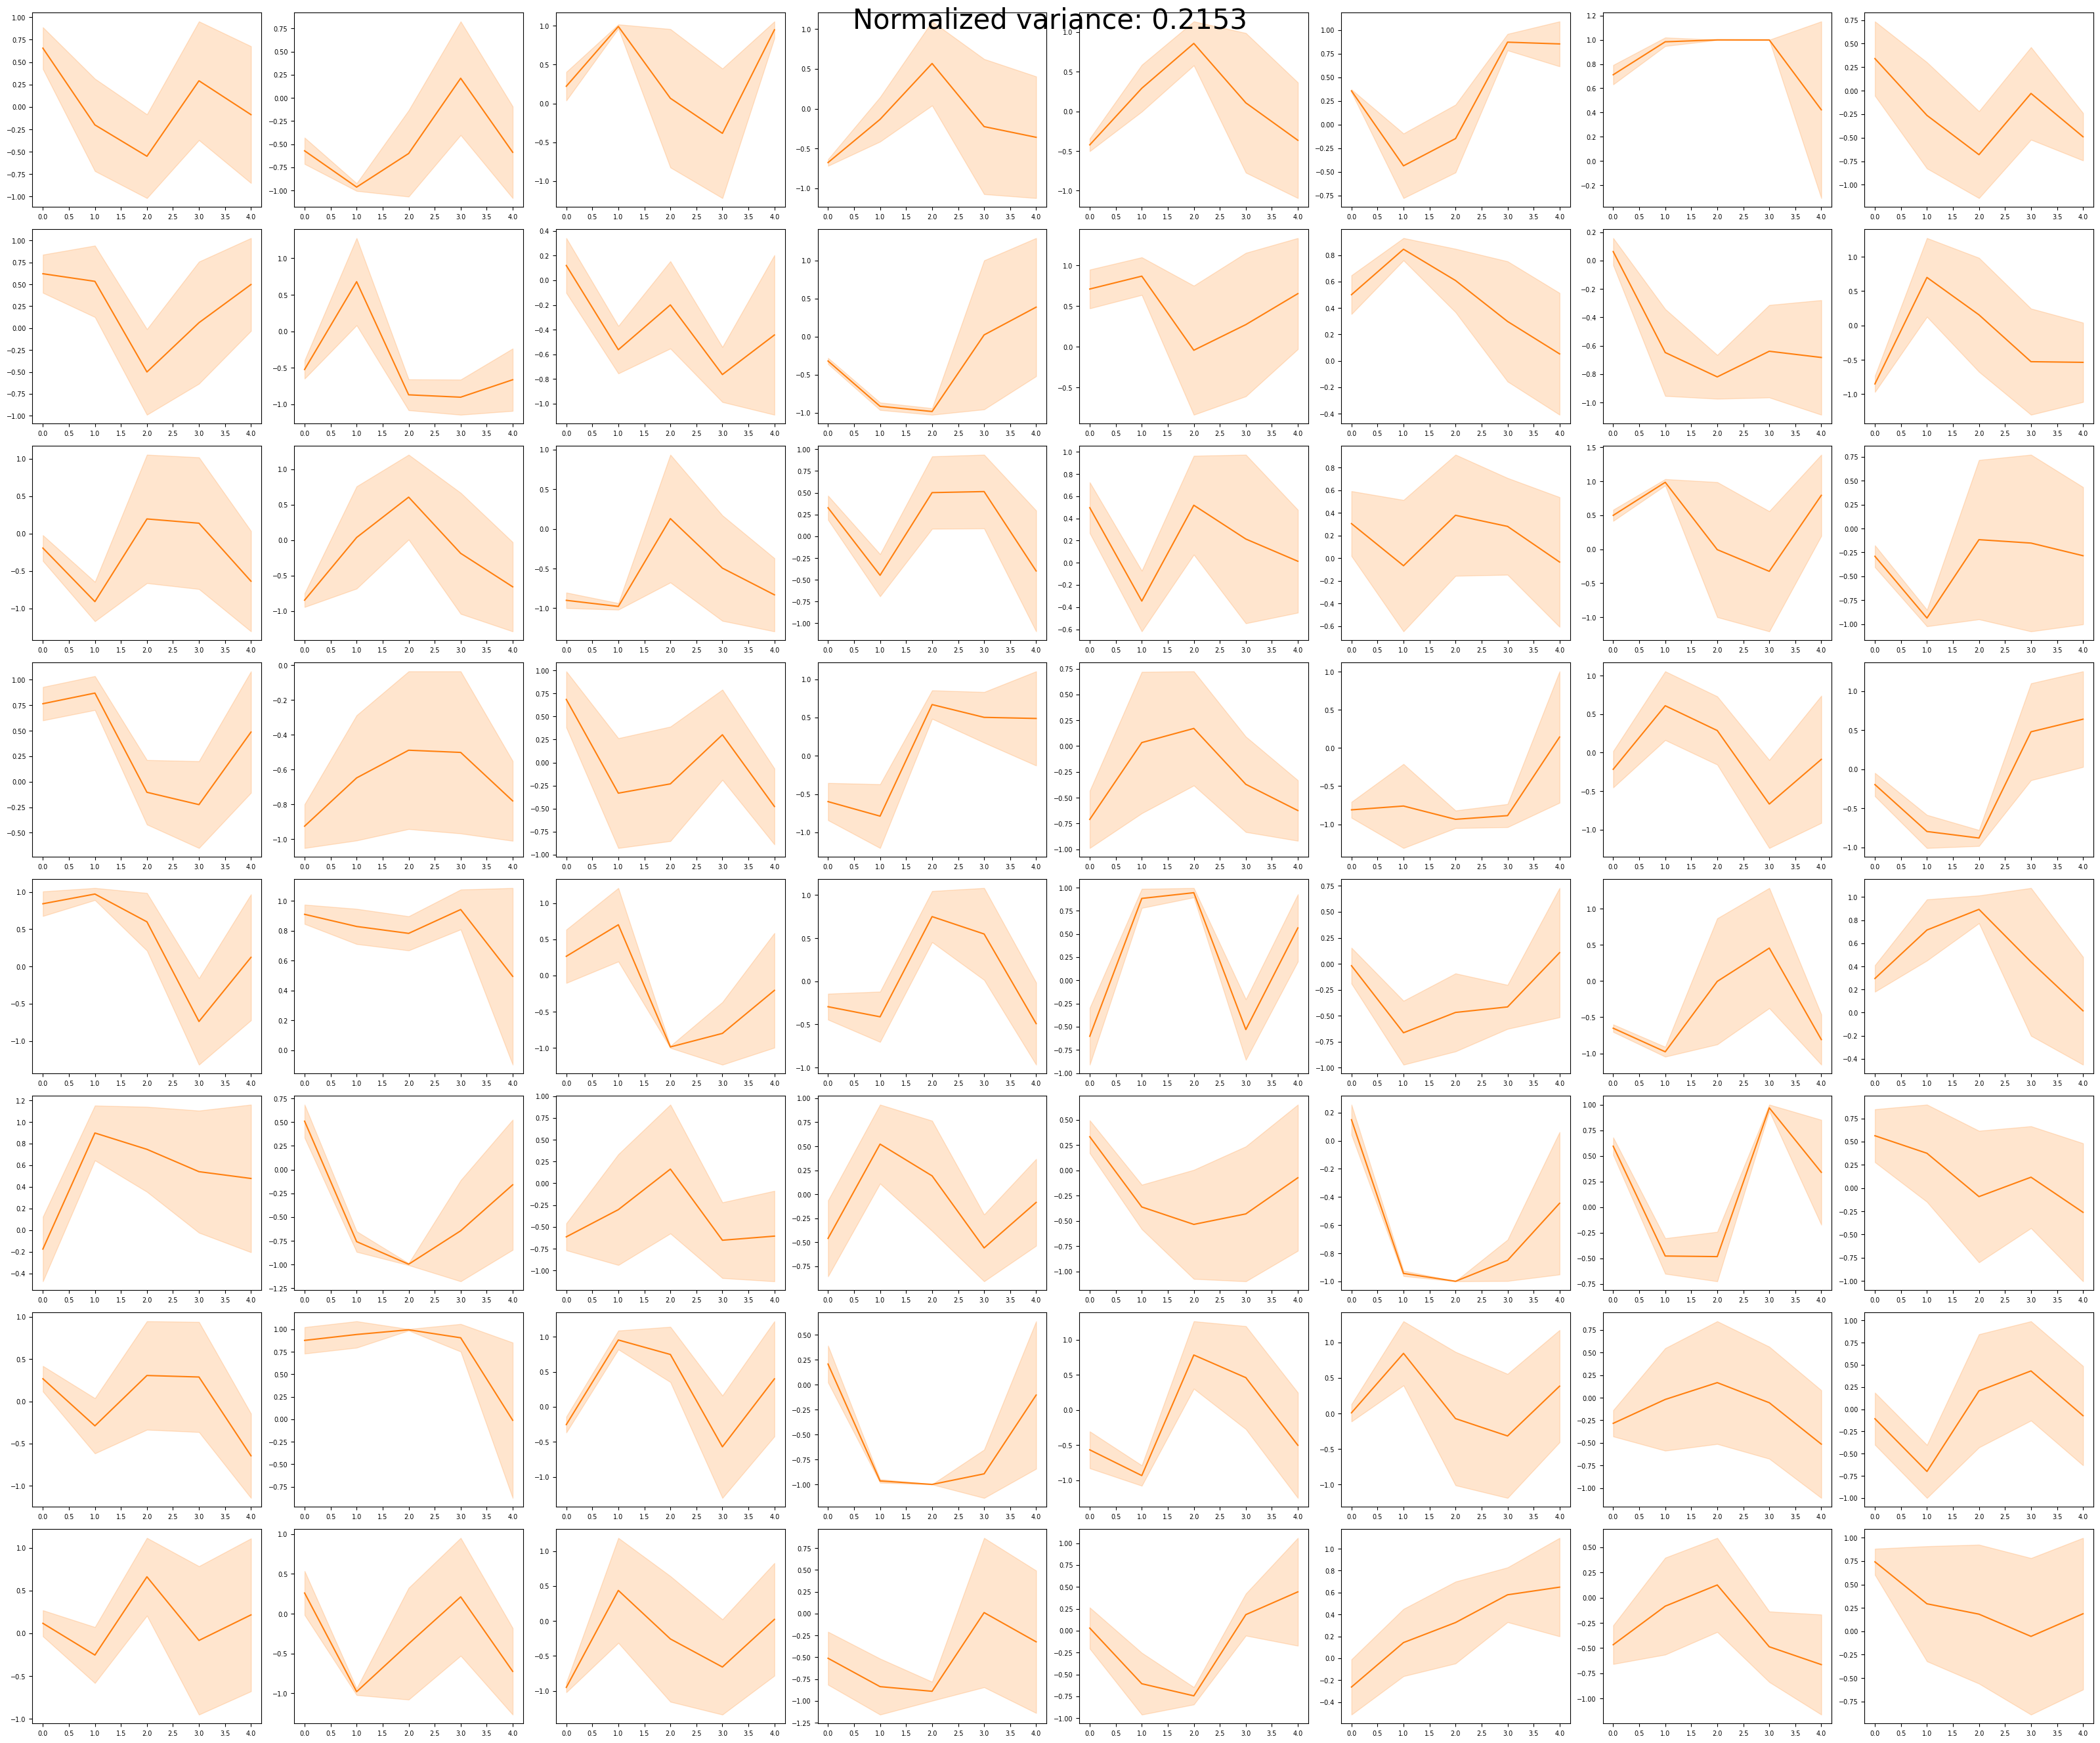

In [ ]:
plot_activity(hidden_size, simple_net, idxs, 'C1')